### Setup

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel("GSS_edited_values.xlsx", sheet_name="GSS_edited", keep_default_na=False)

print(df.shape) # should be (1500, 24)

NOT_APPLICABLE = {"not applicable", "nap"}
NON_SUBSTANTIVE = {"don't know", "dk", "no answer", "na", "refused", "not available", ""}

def classify(v):
    """Return valid / not_applicable / nonsub / system_missing"""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "system_missing"
    s = str(v).strip().lower()
    if s in NOT_APPLICABLE: return "not_applicable"
    if s in NON_SUBSTANTIVE: return "nonsub"
    return "valid"

(1500, 24)


### age_group and frequency-table helper

In [6]:
age_num = pd.to_numeric(df["age"], errors="coerce")   # "No answer" -> NaN
labels = ["18–24","25–34","35–44","45–54","55–64","65–74","75+"]
df["age_group"] = pd.cut(age_num, bins=[17,24,34,44,54,64,74,np.inf], labels=labels)
df["age_group"] = df["age_group"].cat.add_categories("No answer").fillna("No answer")

def freq(s, order=None):
    t = s.value_counts(dropna=False)
    if order:
        t = t.reindex(order + [x for x in t.index if x not in order])
    out = pd.DataFrame({"Count": t, "Percent": (t / len(s) * 100).round(2)})
    out.loc["Total"] = [out["Count"].sum(), out["Percent"].sum().round(1)]
    return out

inc_order = ["LT $1000","$1000-2999","$3000-3999","$4000-4999","$5000-5999",
             "$6000-6999","$7000-7999","$8000-9999","$10000-12499","$12500-14999",
             "$15000-17499","$17500-19999","$20000-22499","$22500-24999",
             "$25000-29999","$30000-34999","$35000-39999","$40000-49999",
             "$50000-59999","$60000-74999","$75000+","NAP","REFUSED","DK","NA"]
happy_order = ["VERY HAPPY","PRETTY HAPPY","NOT TOO HAPPY","No answer"]

freq(df["age_group"], order=labels + ["No answer"])
freq(df["sex"])
freq(df["marital"])
freq(df["happy"], order=happy_order)
freq(df["rincom91"], order=inc_order)

,Count,Percent
rincom91,,
LT $1000,26.0,1.73
$1000-2999,36.0,2.40
$3000-3999,30.0,2.00
$4000-4999,24.0,1.60
$5000-5999,23.0,1.53
$6000-6999,23.0,1.53
$7000-7999,15.0,1.00
$8000-9999,31.0,2.07
$10000-12499,55.0,3.67


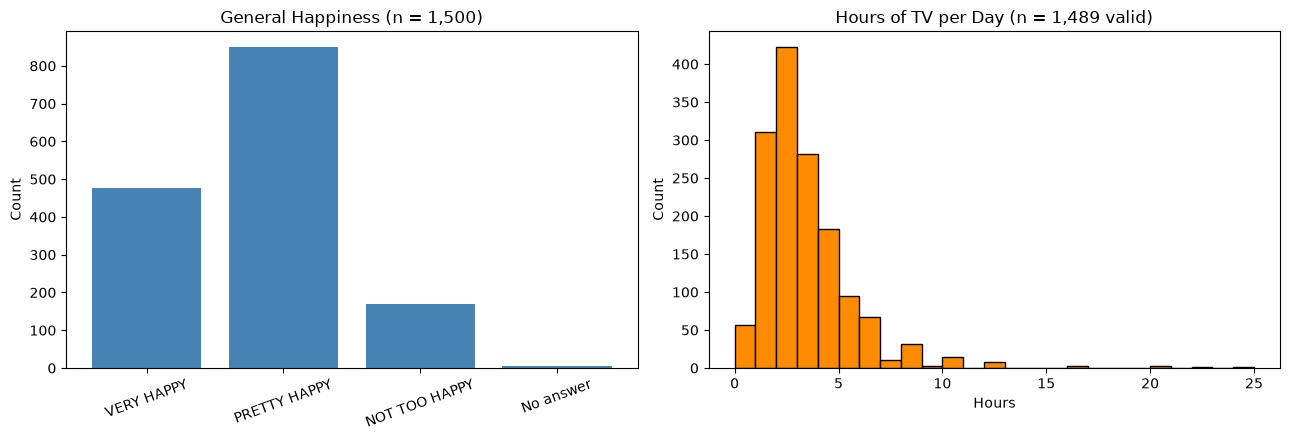

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# 1) Bar chart, categorical variable
h = df["happy"].value_counts().reindex(happy_order)
ax[0].bar(h.index, h.values, color="steelblue")
ax[0].set_title("General Happiness (n = 1,500)")
ax[0].set_ylabel("Count"); ax[0].tick_params(axis="x", rotation=20)

# 2) Histogram, tvhours (numeric values only; "NA" excluded)
tv = pd.to_numeric(df["tvhours"], errors="coerce").dropna()
ax[1].hist(tv, bins=range(0, 26), edgecolor="black", color="darkorange")
ax[1].set_title(f"Hours of TV per Day (n = {len(tv):,} valid)")
ax[1].set_xlabel("Hours"); ax[1].set_ylabel("Count")

plt.tight_layout(); plt.show()

In [8]:
vars_ = {"rincom91": "Income (rincom91)", "satjob": "Job satisfaction (satjob)",
         "happy": "General happiness (happy)", "postlife": "Life after death (postlife)",
         "tvhours": "Television hours (tvhours)"}

rows = []
for v, name in vars_.items():
    c = df[v].map(classify).value_counts()
    valid, nap = c.get("valid", 0), c.get("not_applicable", 0)
    nonsub, sysm = c.get("nonsub", 0), c.get("system_missing", 0)
    rows.append([name, valid, nap, nonsub, sysm, len(df),
                 round((nonsub + sysm) / len(df) * 100, 2)])

miss_table = pd.DataFrame(rows, columns=[
    "Variable","Valid substantive","Not applicable",
    "DK / refused / no answer / blank","System missing","Total records",
    "Non-substantive missing %"])
miss_table

,Variable,Valid substantive,Not applicable,DK / refused / no answer / blank,System missing,Total records,Non-substantive missing %
0,Income (rincom91),947,493,60,0,1500,4.00
1,Job satisfaction (satjob),1143,309,48,0,1500,3.20
2,General happiness (happy),1495,0,5,0,1500,0.33
3,Life after death (postlife),906,485,109,0,1500,7.27
4,Television hours (tvhours),1489,0,11,0,1500,0.73


In [9]:
tv = pd.to_numeric(df["tvhours"], errors="coerce")
print(tv.describe())
print("Zeros (legitimate):", (tv == 0).sum())
print("Values > 16:", (tv > 16).sum(), "| values > 18:", (tv > 18).sum())
print(tv[tv > 16].value_counts().sort_index())

count    1489.000000
mean        2.899933
std         2.238184
min         0.000000
25%         2.000000
50%         2.000000
75%         4.000000
max        24.000000
Name: tvhours, dtype: float64
Zeros (legitimate): 56
Values > 16: 4 | values > 18: 4
tvhours
20.0    2
22.0    1
24.0    1
Name: count, dtype: int64


In [10]:
def missing_by_group(data, outcome, group):
    d = data.assign(status=data[outcome].map(classify))
    g = d.groupby(group, observed=True)["status"]
    out = pd.DataFrame({
        "Total": g.size(),
        "Not applicable": g.apply(lambda s: (s == "not_applicable").sum()),
        "Missing": g.apply(lambda s: s.isin(["nonsub", "system_missing"]).sum()),
    })
    out["Missing % (of all)"] = (out["Missing"] / out["Total"] * 100).round(2)
    out["Missing % (excl. N/A)"] = (
        out["Missing"] / (out["Total"] - out["Not applicable"]) * 100).round(2)
    return out

missing_by_group(df, "rincom91", "age_group")   # or "sex" / "marital"

,Total,Not applicable,Missing,Missing % (of all),Missing % (excl. N/A)
age_group,,,,,
18–24,128,46,1,0.78,1.22
25–34,304,53,8,2.63,3.19
35–44,368,55,15,4.08,4.79
45–54,243,42,23,9.47,11.44
55–64,167,60,2,1.20,1.87
65–74,163,130,3,1.84,9.09
75+,122,105,6,4.92,35.29
No answer,5,2,2,40.00,66.67


Kept 1494 of 1500 rows; dropped 6 with non-substantive happy/marital


happy,VERY HAPPY,PRETTY HAPPY,NOT TOO HAPPY,n
marital,,,,
DIVORCED,20.8,62.3,17.0,212
MARRIED,39.5,53.5,7.1,793
NEVER MARRIED,24.9,64.9,10.2,285
SEPARATED,25.0,42.5,32.5,40
WIDOWED,23.2,55.5,21.3,164


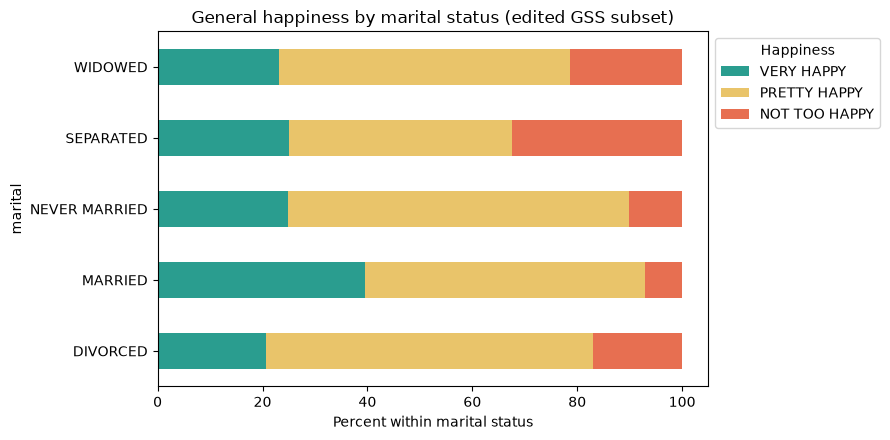

In [11]:
mask = (df["happy"].map(classify) == "valid") & (df["marital"].map(classify) == "valid")
sub = df[mask]
print(f"Kept {len(sub)} of {len(df)} rows; dropped {len(df) - len(sub)} with non-substantive happy/marital")

ct = pd.crosstab(sub["marital"], sub["happy"])[happy_order[:3]]
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct_pct.round(1).assign(n=ct.sum(axis=1))
display(result)

ct_pct.plot(kind="barh", stacked=True, figsize=(9, 4.5),
            color=["#2a9d8f", "#e9c46a", "#e76f51"])
plt.xlabel("Percent within marital status"); plt.legend(title="Happiness", bbox_to_anchor=(1, 1))
plt.title("General happiness by marital status (edited GSS subset)")
plt.tight_layout(); plt.show()